# RaphIA · Prueba de campo con el pipeline completo

**Qué hace este notebook:** pasa tus fotos de campo por el mismo proceso que el sistema:

1. **YOLOv8m** detecta cada hoja de la foto.
2. Cada hoja se recorta y **EfficientNet-B2** la clasifica (tizón temprano, sana o tizón tardío).
3. Una **regla** decide el diagnóstico de la foto completa.

Después calcula las métricas que pidieron los revisores y genera las figuras en inglés. **Solo usa CPU** (no hace falta GPU).

### 1. Instalación de librerías
`pillow-heif` permite leer las fotos HEIC del iPhone.

In [1]:
!pip install -q ultralytics onnxruntime statsmodels scikit-learn pillow-heif

### 2. Montar Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 3. Carpetas
Revisa `CARPETA_FOTOS`: debe tener una subcarpeta por clase.

In [3]:
import os

RAIZ = "/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)"
CARPETA_FOTOS = f"{RAIZ}/Imagenes"
CARPETA_YOLO = f"{RAIZ}/Modelos/Resultados/01_YOLO"
CARPETA_CLASIFICADORES = f"{RAIZ}/Modelos/Resultados/02_Clasificadores"
CARPETA_RESULTADOS = f"{RAIZ}/Modelos/Resultados/03_Prueba_Campo"

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
print("Contenido de la carpeta de fotos:", os.listdir(CARPETA_FOTOS))

Contenido de la carpeta de fotos: ['HOJAS SANAS', 'TIZON TEMPRANO', 'TIZON TARDIO']


### 4. Subcarpeta de cada clase
Pon el nombre exacto de cada subcarpeta, tal como aparece en la salida anterior.

In [4]:
CARPETAS_CLASE = {
    "Late Blight": f"{CARPETA_FOTOS}/TIZON TARDIO",
    "Early Blight": f"{CARPETA_FOTOS}/TIZON TEMPRANO",
    "Healthy": f"{CARPETA_FOTOS}/HOJAS SANAS",
}
for clase, carpeta in CARPETAS_CLASE.items():
    print(clase, "->", os.path.exists(carpeta))

Late Blight -> True
Early Blight -> True
Healthy -> True


### 5. Parámetros del sistema (los mismos de `main.py`)

In [5]:
CONF_DETECTOR = 0.50          # confianza mínima para aceptar una hoja detectada
UMBRAL_ENFERMA = 0.70         # confianza mínima para declarar una hoja enferma
CLASES = ["Early Blight", "Healthy", "Late Blight"]   # orden con el que se entrenó EfficientNet

### 6. Lista de fotos

In [6]:
from PIL import Image
from pillow_heif import register_heif_opener
register_heif_opener()

fotos = []
for clase, carpeta in CARPETAS_CLASE.items():
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith((".jpg", ".jpeg", ".png", ".heic", ".heif")):
            fotos.append({"archivo": f"{carpeta}/{archivo}", "real": clase})

import pandas as pd
fotos = pd.DataFrame(fotos)
fotos.to_csv(f"{CARPETA_RESULTADOS}/lista_fotos.csv", index=False)
fotos["real"].value_counts()

,count
real,
Late Blight,254
Early Blight,193
Healthy,43


### 7. Formato real de cada foto
Un archivo `.jpg` del iPhone puede ser HEIC por dentro. Esta celda lo muestra.

In [7]:
def formato(ruta):
    try:
        return Image.open(ruta).format
    except Exception:
        return "ILEGIBLE"

fotos["formato"] = fotos["archivo"].apply(formato)
fotos["formato"].value_counts()

,count
formato,
JPEG,464
HEIF,26


Si alguna foto sale `ILEGIBLE`, se quita de la prueba con esta celda (y se muestra cuál fue).

In [8]:
print(fotos[fotos["formato"] == "ILEGIBLE"]["archivo"].tolist())
fotos = fotos[fotos["formato"] != "ILEGIBLE"].reset_index(drop=True)
fotos["real"].value_counts()

[]


,count
real,
Late Blight,254
Early Blight,193
Healthy,43


### 8. Función para leer cualquier foto (JPG, PNG o HEIC)

In [9]:
import cv2
import numpy as np
from PIL import ImageOps

def leer_foto(ruta):
    imagen = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")   # respeta la orientación del celular
    return np.array(imagen)                                              # RGB

### 9. Cargar el detector YOLOv8m (el reentrenado en el notebook 01)

In [10]:
from ultralytics import YOLO

detector = YOLO(f"{CARPETA_YOLO}/yolov8m_best.onnx", task="detect")
print("Detector cargado")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Detector cargado


### 10. Función: detectar las hojas de una foto
Devuelve las cajas `(x1, y1, x2, y2)` de cada hoja.

In [11]:
def detectar_hojas(foto_rgb):
    resultado = detector.predict(foto_rgb[:, :, ::-1].copy(), conf=CONF_DETECTOR, imgsz=640, device="cpu", verbose=False)[0]
    cajas = resultado.boxes.xyxy.cpu().numpy().astype(int).tolist()
    return [c for c in cajas if (c[2] - c[0]) >= 5 and (c[3] - c[1]) >= 5]

### 11. Cargar los clasificadores
Cada uno con su tamaño de entrada y su forma de normalizar.

In [12]:
import onnxruntime as ort

opciones = ort.SessionOptions()
opciones.intra_op_num_threads = 4          # 4 vCPU, como Cloud Run

def cargar(ruta):
    return ort.InferenceSession(ruta, opciones, providers=["CPUExecutionProvider"]) if os.path.exists(ruta) else None

CLASIFICADORES = {
    "EfficientNet-B2": (cargar(f"{CARPETA_CLASIFICADORES}/efficientnet_b2.onnx"), 288, "raw255"),
    "EfficientNet-B0": (cargar(f"{CARPETA_CLASIFICADORES}/efficientnet_b0.onnx"), 224, "raw255"),
    "ResNet-50": (cargar(f"{CARPETA_CLASIFICADORES}/resnet50.onnx"), 224, "raw255"),
    "MobileNetV3-Large": (cargar(f"{CARPETA_CLASIFICADORES}/mobilenet_v3_large.onnx"), 224, "raw255"),
}
for nombre, (sesion, tamano, modo) in CLASIFICADORES.items():
    print(nombre, "->", "cargado" if sesion else "NO ENCONTRADO")

EfficientNet-B2 -> cargado
EfficientNet-B0 -> cargado
ResNet-50 -> cargado
MobileNetV3-Large -> cargado


### 12. Función: clasificar una hoja
Devuelve la clase y la confianza.

In [13]:
MEDIA = np.array([0.485, 0.456, 0.406], np.float32)
DESV = np.array([0.229, 0.224, 0.225], np.float32)

def clasificar_hoja(hoja_rgb, nombre_clasificador):
    sesion, tamano, modo = CLASIFICADORES[nombre_clasificador]
    x = cv2.resize(hoja_rgb, (tamano, tamano)).astype(np.float32)
    salida = sesion.run(None, {sesion.get_inputs()[0].name: x.transpose(2, 0, 1)[None].astype(np.float32)})[0][0]
    probabilidades = np.exp(salida - salida.max()) / np.exp(salida - salida.max()).sum()
    k = int(probabilidades.argmax())
    return CLASES[k], float(probabilidades[k])

### 13. Regla para decidir el diagnóstico de la foto
1. Si **al menos una hoja** está enferma con confianza ≥ 70 % → la foto es **enferma** (gana la de mayor confianza).
2. Si no, y hay hojas sanas → la foto es **sana**.
3. Si solo hay hojas enfermas con poca confianza → la más probable.
4. Si no se detectó ninguna hoja → **sin hoja**.

In [14]:
def decidir_foto(hojas):
    if not hojas:
        return "No leaf detected", 0.0
    enfermas = [h for h in hojas if h[0] != "Healthy" and h[1] >= UMBRAL_ENFERMA]
    if enfermas:
        return max(enfermas, key=lambda h: h[1])
    sanas = [h for h in hojas if h[0] == "Healthy"]
    if sanas:
        return max(sanas, key=lambda h: h[1])
    return max(hojas, key=lambda h: h[1])

### 14. Prueba con una sola foto
Para ver paso a paso qué hace el sistema antes de procesarlas todas.

In [15]:
foto = leer_foto(fotos.iloc[0]["archivo"])
cajas = detectar_hojas(foto)
print("Foto:", os.path.basename(fotos.iloc[0]["archivo"]), "| clase real:", fotos.iloc[0]["real"])
print("Hojas detectadas:", len(cajas))
hojas = []
for x1, y1, x2, y2 in cajas:
    resultado = clasificar_hoja(foto[y1:y2, x1:x2], "EfficientNet-B2")
    hojas.append(resultado)
    print("  hoja", (x1, y1, x2, y2), "->", resultado[0], f"{resultado[1]*100:.1f}%")
print("Diagnóstico de la foto:", decidir_foto(hojas))

Loading /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnx'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 5 packages in 652ms
Prepared 1 package in 360ms
Installed 1 package in 35ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 1.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.32.0 with CPUExecutionProvider
Foto: IMG_LB001.jpg | clase real: Late Blight
Hojas detectadas: 2
  hoja (651, 651, 2965, 3392) -> Late Blight 99.0%
  hoja (12, 0, 1230, 1291) -> Healthy 99.8%
Diagnóstico de la foto: ('Late Blight', 0.9896429777145386)


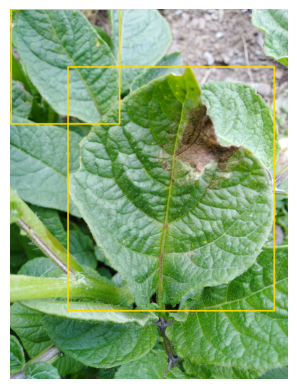

In [16]:
import matplotlib.pyplot as plt
vista = foto.copy()
for x1, y1, x2, y2 in cajas:
    cv2.rectangle(vista, (x1, y1), (x2, y2), (255, 215, 0), max(2, vista.shape[1] // 200))
plt.imshow(vista); plt.axis("off"); plt.show()

### 15. Detectar las hojas en todas las fotos (una sola vez)
Se guardan las cajas para no repetir la detección con cada clasificador. También se mide el tiempo.

In [17]:
import time

cajas_por_foto, tiempos_deteccion = [], []
for i, ruta in enumerate(fotos["archivo"]):
    foto = leer_foto(ruta)
    inicio = time.perf_counter()
    cajas_por_foto.append(detectar_hojas(foto))
    tiempos_deteccion.append((time.perf_counter() - inicio) * 1000)
    if (i + 1) % 50 == 0:
        print(i + 1, "de", len(fotos))

fotos["n_hojas"] = [len(c) for c in cajas_por_foto]
print("Fotos sin ninguna hoja detectada:", (fotos["n_hojas"] == 0).sum())
print("Hojas por foto (promedio):", round(fotos["n_hojas"].mean(), 2))

50 de 490
100 de 490
150 de 490
200 de 490
250 de 490
300 de 490
350 de 490
400 de 490
450 de 490
Fotos sin ninguna hoja detectada: 0
Hojas por foto (promedio): 1.89


### 16. Función: diagnosticar todas las fotos con un clasificador

In [18]:
def diagnosticar_todas(nombre_clasificador, usar_yolo=True):
    diagnosticos, confianzas, tiempos = [], [], []
    for ruta, cajas in zip(fotos["archivo"], cajas_por_foto):
        foto = leer_foto(ruta)
        inicio = time.perf_counter()
        if usar_yolo:
            hojas = [clasificar_hoja(foto[y1:y2, x1:x2], nombre_clasificador) for x1, y1, x2, y2 in cajas]
        else:
            hojas = [clasificar_hoja(foto, nombre_clasificador)]     # foto completa, sin recortar
        clase, confianza = decidir_foto(hojas)
        tiempos.append((time.perf_counter() - inicio) * 1000)
        diagnosticos.append(clase); confianzas.append(confianza)
    return diagnosticos, confianzas, tiempos

### 17. Función: métricas de un diagnóstico

In [19]:
from sklearn.metrics import precision_recall_fscore_support, balanced_accuracy_score
from statsmodels.stats.proportion import proportion_confint

def metricas(predichos):
    reales = fotos["real"]
    aciertos = int((reales == pd.Series(predichos)).sum())
    lo, hi = proportion_confint(aciertos, len(reales), method="wilson")
    _, _, f1, _ = precision_recall_fscore_support(reales, predichos, labels=CLASES, zero_division=0)
    return {"aciertos": aciertos, "total": len(reales), "accuracy_%": round(100 * aciertos / len(reales), 2),
            "IC95_%": (round(100 * lo, 1), round(100 * hi, 1)),
            "balanced_accuracy_%": round(100 * balanced_accuracy_score(reales, predichos), 2),
            "macro_F1": round(float(np.mean(f1)), 4)}

### 18. Pipeline principal: YOLOv8m + EfficientNet-B2
Este es el resultado que va al paper.

In [20]:
fotos["pred"], fotos["confianza"], tiempos_clasificacion = diagnosticar_todas("EfficientNet-B2")
fotos.to_csv(f"{CARPETA_RESULTADOS}/predicciones_pipeline_principal.csv", index=False)
principal = metricas(fotos["pred"])
principal

{'aciertos': 455,
 'total': 490,
 'accuracy_%': 92.86,
 'IC95_%': (90.2, 94.8),
 'balanced_accuracy_%': np.float64(91.81),
 'macro_F1': 0.9028}

### 19. Métricas por clase del pipeline principal

In [21]:
def wilson(k, n):
    lo, hi = proportion_confint(k, n, method="wilson")
    return f"{100*lo:.1f}–{100*hi:.1f}"

precision, recall, f1, n = precision_recall_fscore_support(fotos["real"], fotos["pred"], labels=CLASES, zero_division=0)
por_clase = pd.DataFrame({"clase": CLASES, "n": n, "precision": precision.round(4), "recall": recall.round(4), "F1": f1.round(4)})
por_clase["aciertos"] = [int(((fotos["real"] == c) & (fotos["pred"] == c)).sum()) for c in CLASES]
por_clase["IC95_recall_%"] = [wilson(k, m) for k, m in zip(por_clase["aciertos"], por_clase["n"])]
por_clase.to_csv(f"{CARPETA_RESULTADOS}/metricas_por_clase.csv", index=False)
por_clase

,clase,n,precision,recall,F1,aciertos,IC95_recall_%
0,Early Blight,193,0.8932,0.9534,0.9223,184,91.4–97.5
1,Healthy,43,0.7917,0.8837,0.8352,38,75.5–94.9
2,Late Blight,254,0.9873,0.9173,0.9510,233,87.7–94.5


### 20. Matriz de confusión del pipeline principal

In [22]:
from sklearn.metrics import confusion_matrix

columnas = CLASES + ["No leaf detected"]
matriz = confusion_matrix(fotos["real"], fotos["pred"], labels=columnas)[:3]
pd.DataFrame(matriz, index=[f"real {c}" for c in CLASES], columns=[f"pred {c}" for c in columnas])

,pred Early Blight,pred Healthy,pred Late Blight,pred No leaf detected
real Early Blight,184,6,3,0
real Healthy,5,38,0,0
real Late Blight,17,4,233,0


### 21. Errores del pipeline principal
Lista de fotos mal clasificadas, para revisarlas.

In [23]:
errores = fotos[fotos["real"] != fotos["pred"]][["archivo", "real", "pred", "confianza", "n_hojas"]]
errores.to_csv(f"{CARPETA_RESULTADOS}/errores_pipeline_principal.csv", index=False)
print("Total de errores:", len(errores))
errores["pred"].groupby(errores["real"]).value_counts()

Total de errores: 35


real          pred        
Early Blight  Healthy          6
              Late Blight      3
Healthy       Early Blight     5
Late Blight   Early Blight    17
              Healthy          4
Name: count, dtype: int64

### 22. Tiempo por foto en CPU (detección + clasificación)

In [24]:
total = np.array(tiempos_deteccion) + np.array(tiempos_clasificacion)
latencia = {"deteccion_ms": round(float(np.mean(tiempos_deteccion)), 1),
            "clasificacion_ms": round(float(np.mean(tiempos_clasificacion)), 1),
            "total_ms": round(float(total.mean()), 1),
            "total_p95_ms": round(float(np.percentile(total, 95)), 1)}
print("CPU:", os.popen("lscpu | grep 'Model name'").read().strip())
latencia

CPU: Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz


{'deteccion_ms': 1967.3,
 'clasificacion_ms': 457.2,
 'total_ms': 2424.5,
 'total_p95_ms': 3680.9}

### 23. Comparaciones (una variante por celda)
Todas usan las mismas fotos y las mismas hojas detectadas.

In [25]:
comparacion = {"YOLOv8m + EfficientNet-B2": principal}

**a) Sin YOLO**: EfficientNet-B2 sobre la foto completa (justifica usar dos etapas)

In [26]:
pred, _, _ = diagnosticar_todas("EfficientNet-B2", usar_yolo=False)
comparacion["EfficientNet-B2 sin YOLO"] = metricas(pred)
comparacion["EfficientNet-B2 sin YOLO"]

{'aciertos': 389,
 'total': 490,
 'accuracy_%': 79.39,
 'IC95_%': (75.6, 82.7),
 'balanced_accuracy_%': np.float64(82.95),
 'macro_F1': 0.7654}

**b) YOLOv8m + EfficientNet-B0**

In [27]:
pred, _, _ = diagnosticar_todas("EfficientNet-B0")
comparacion["YOLOv8m + EfficientNet-B0"] = metricas(pred)
comparacion["YOLOv8m + EfficientNet-B0"]

{'aciertos': 406,
 'total': 490,
 'accuracy_%': 82.86,
 'IC95_%': (79.3, 85.9),
 'balanced_accuracy_%': np.float64(85.11),
 'macro_F1': 0.7757}

**c) YOLOv8m + ResNet-50**

In [28]:
pred, _, _ = diagnosticar_todas("ResNet-50")
comparacion["YOLOv8m + ResNet-50"] = metricas(pred)
comparacion["YOLOv8m + ResNet-50"]

{'aciertos': 427,
 'total': 490,
 'accuracy_%': 87.14,
 'IC95_%': (83.9, 89.8),
 'balanced_accuracy_%': np.float64(90.15),
 'macro_F1': 0.8542}

**d) YOLOv8m + MobileNetV3-Large**

In [29]:
pred, _, _ = diagnosticar_todas("MobileNetV3-Large")
comparacion["YOLOv8m + MobileNetV3-Large"] = metricas(pred)
comparacion["YOLOv8m + MobileNetV3-Large"]

{'aciertos': 458,
 'total': 490,
 'accuracy_%': 93.47,
 'IC95_%': (90.9, 95.3),
 'balanced_accuracy_%': np.float64(91.13),
 'macro_F1': 0.9156}

### 24. Tabla comparativa en campo

In [30]:
tabla = pd.DataFrame(comparacion).T
tabla.to_csv(f"{CARPETA_RESULTADOS}/comparacion_campo.csv")
tabla

,aciertos,total,accuracy_%,IC95_%,balanced_accuracy_%,macro_F1
YOLOv8m + EfficientNet-B2,455,490,92.86,"(90.2, 94.8)",91.81,0.9028
EfficientNet-B2 sin YOLO,389,490,79.39,"(75.6, 82.7)",82.95,0.7654
YOLOv8m + EfficientNet-B0,406,490,82.86,"(79.3, 85.9)",85.11,0.7757
YOLOv8m + ResNet-50,427,490,87.14,"(83.9, 89.8)",90.15,0.8542
YOLOv8m + MobileNetV3-Large,458,490,93.47,"(90.9, 95.3)",91.13,0.9156


### 25. Figura: matriz de confusión en campo

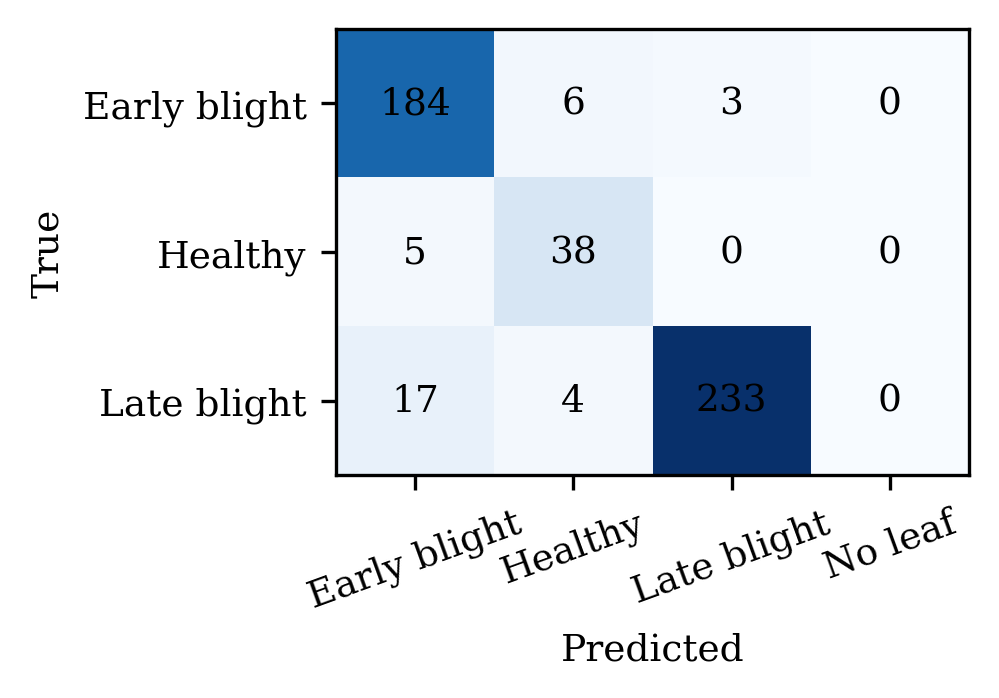

In [31]:
plt.rcParams.update({"font.family": "serif", "font.size": 9})
etiquetas_x = ["Early blight", "Healthy", "Late blight", "No leaf"]
etiquetas_y = ["Early blight", "Healthy", "Late blight"]
fig, ax = plt.subplots(figsize=(3.4, 2.4), dpi=300)
ax.imshow(matriz, cmap="Blues", aspect="auto")
for i in range(3):
    for j in range(4):
        ax.text(j, i, matriz[i, j], ha="center", va="center")
ax.set_xticks(range(4)); ax.set_xticklabels(etiquetas_x, rotation=20)
ax.set_yticks(range(3)); ax.set_yticklabels(etiquetas_y)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
fig.tight_layout()
fig.savefig(f"{CARPETA_RESULTADOS}/fig_field_confusion_matrix.png", bbox_inches="tight")
plt.show()

### 26. Figura: un ejemplo correcto por clase (Figura 8 del paper)

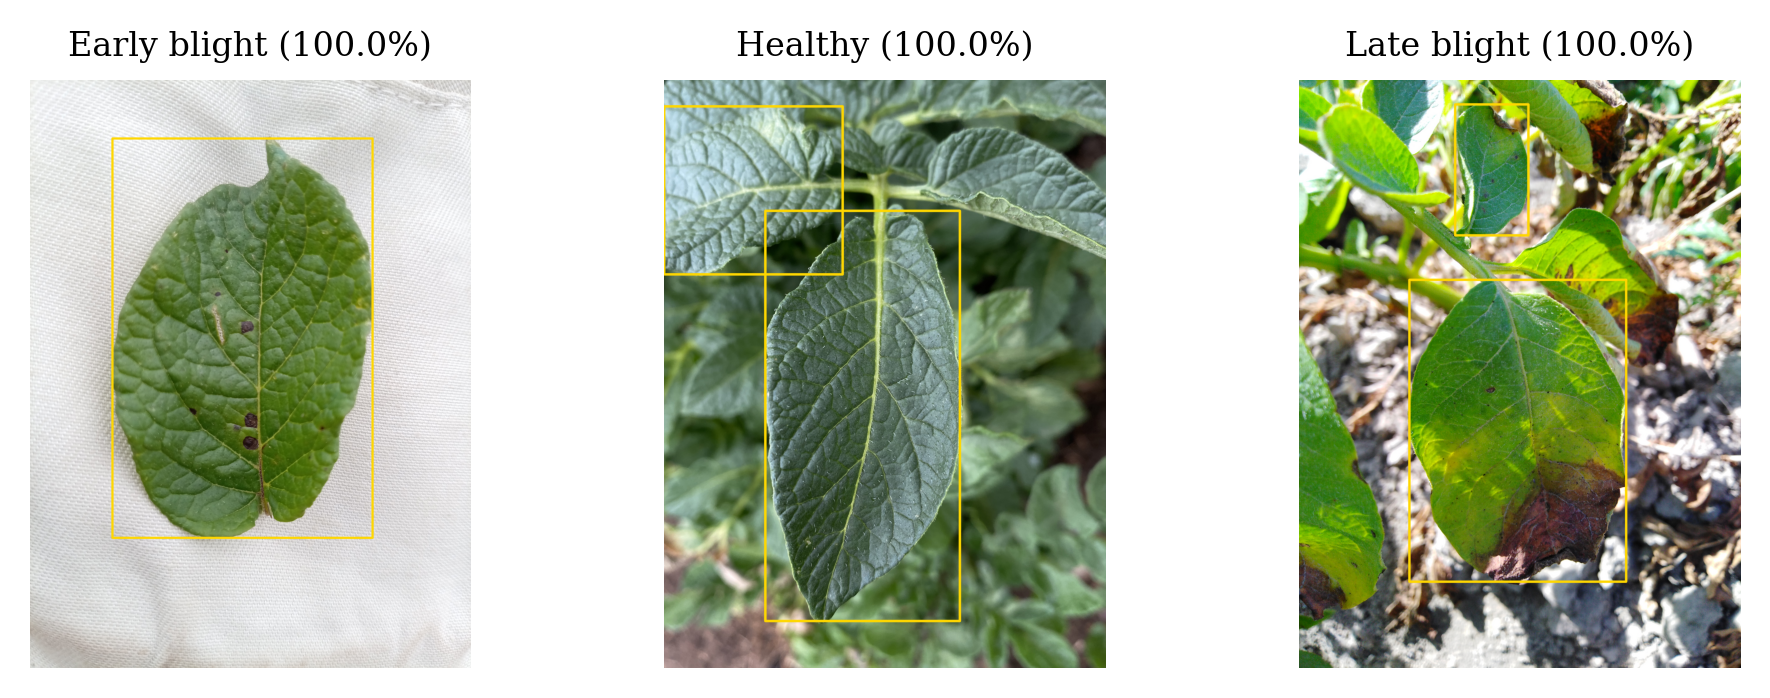

In [32]:
nombres = {"Early Blight": "Early blight", "Healthy": "Healthy", "Late Blight": "Late blight"}
fig, ejes = plt.subplots(1, 3, figsize=(6.6, 2.4), dpi=300)
for eje, clase in zip(ejes, CLASES):
    aciertos = fotos[(fotos["real"] == clase) & (fotos["pred"] == clase)].sort_values("confianza", ascending=False)
    fila = aciertos.iloc[0]
    vista = leer_foto(fila["archivo"])
    for x1, y1, x2, y2 in cajas_por_foto[fila.name]:
        cv2.rectangle(vista, (x1, y1), (x2, y2), (255, 215, 0), max(2, vista.shape[1] // 200))
    eje.imshow(vista); eje.axis("off")
    eje.set_title(f"{nombres[clase]} ({fila['confianza']*100:.1f}%)", fontsize=8)
fig.tight_layout()
fig.savefig(f"{CARPETA_RESULTADOS}/fig_field_examples.png", bbox_inches="tight")
plt.show()

### 27. Guardar el resumen
Pásame `resumen_campo.json`, `metricas_por_clase.csv`, `comparacion_campo.csv` y `errores_pipeline_principal.csv`.

In [33]:
import json

resumen = {
    "parametros": {"conf_detector": CONF_DETECTOR, "umbral_enferma": UMBRAL_ENFERMA, "hilos_cpu": 4},
    "fotos_por_clase": fotos["real"].value_counts().to_dict(),
    "formatos": fotos["formato"].value_counts().to_dict(),
    "pipeline_principal": principal,
    "por_clase": por_clase.to_dict(orient="records"),
    "matriz_real_x_pred": matriz.tolist(),
    "latencia": latencia,
    "comparacion": comparacion,
}
json.dump(resumen, open(f"{CARPETA_RESULTADOS}/resumen_campo.json", "w"), indent=2, default=str)
print("Guardado en", CARPETA_RESULTADOS)

Guardado en /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/03_Prueba_Campo
